# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [2]:
# Lectura datos, relación variables, mapas de correlación...
df = pd.read_csv('data/advertising.csv')
df.head()

,Unnamed: 0,TV,radio,newpaper,sales
0,0,230.1,37.8,6s9.2,22100.0
1,1,44.5,39.3,45.1,10400.0
2,2,17.2,45.9,69.3,9300.0
3,3,151.5,41.3,58.5,18500.0
4,4,180.8,10.8,58.4,12900.0


In [3]:
df = df.loc[:,'TV':]  #Quito la primera columna, ya que no aporta nada
df.head()

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0


In [4]:
df.info()   #Veo que no tengo nulos

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        200 non-null    float64
 1   radio     200 non-null    float64
 2   newpaper  200 non-null    str    
 3   sales     200 non-null    float64
dtypes: float64(3), str(1)
memory usage: 6.4 KB


In [5]:
#paso a Float la columna de 'newpaper' porque esta en str
df['newpaper'] = df['newpaper'].str.replace('s', '', regex=False).astype(float)

#corrijo el nombre de la columna
df.rename(columns={'newpaper': 'newspaper'}, inplace=True)

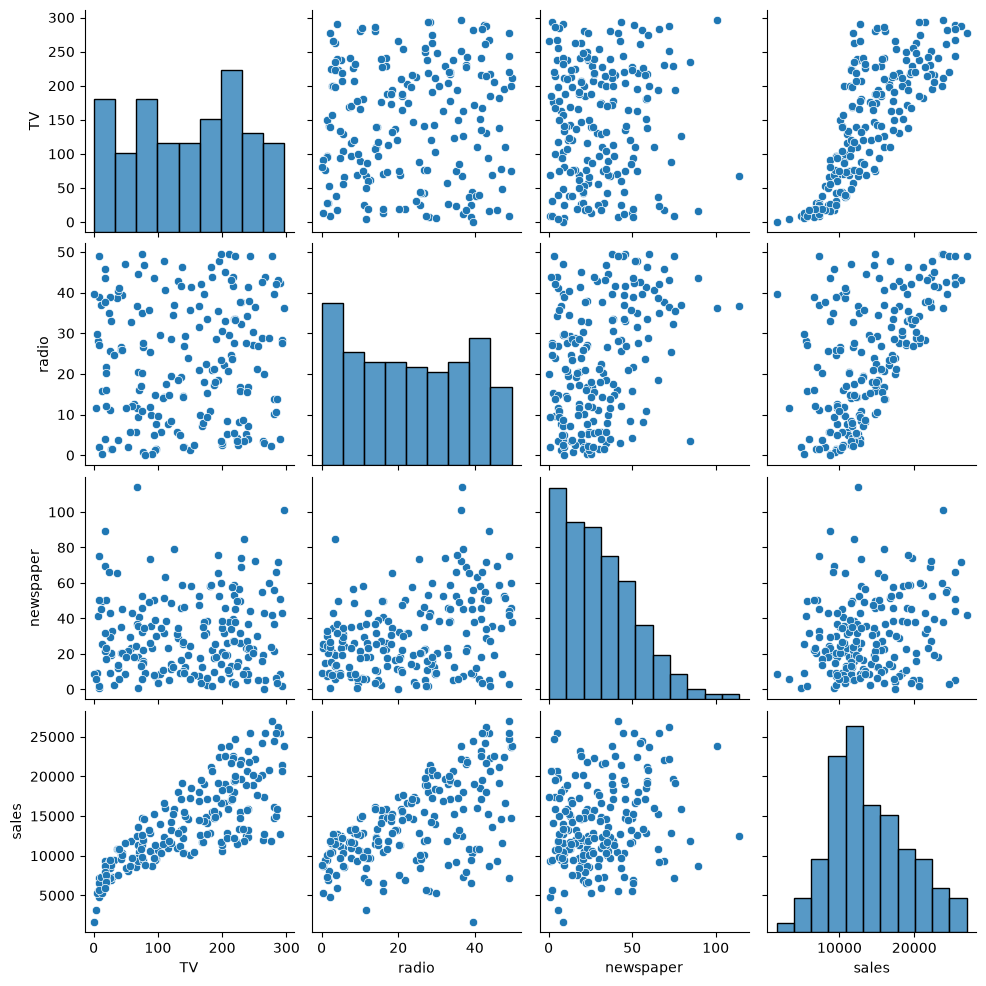

In [6]:
sns.pairplot(df);

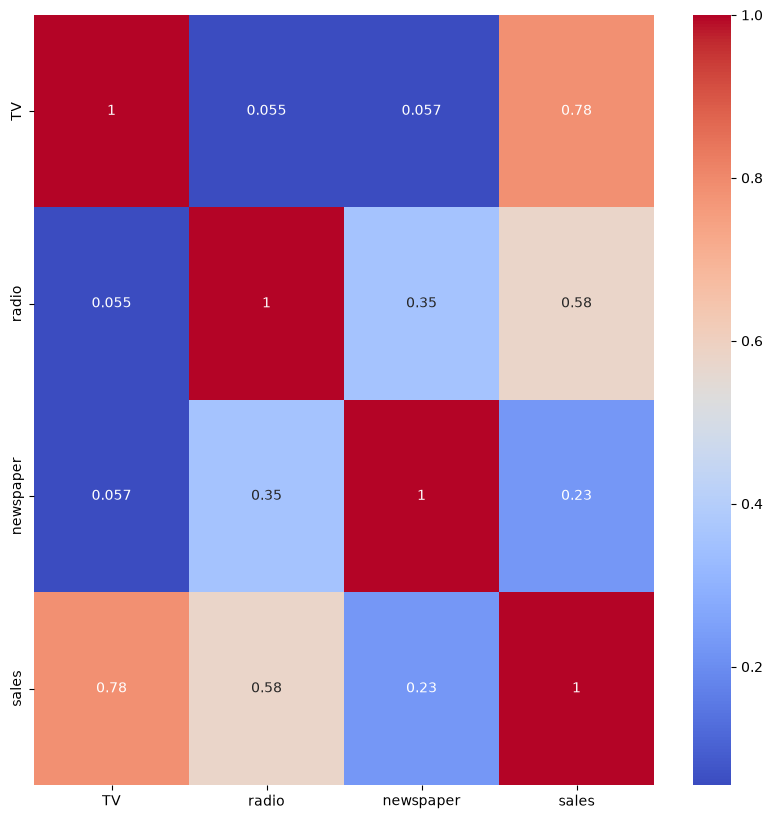

In [7]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm");

## Modelado

In [8]:
# Manipulación datasets, entrenamiento, evaluación, nuevas iteraciones... Prueba modelos sin y con regularización.

In [9]:
#Defino las variables de entrada al modelo y el target
X = df[['TV', 'radio', 'newspaper']]
y = df['sales']

In [10]:
#Separo train y test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
#Escalo
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scal = scaler.fit_transform(X_train)
X_test_scal = scaler.transform(X_test)

In [12]:
#1.REGRESIÓN LINEAL MÚLTIPLE

#Entreno al modelo
from sklearn.linear_model import LinearRegression

lm = LinearRegression()
lm.fit(X_train_scal, y_train)

print(f'Intercepto: {lm.intercept_}')
print(f'Coeficientes: {lm.coef_}')

Intercepto: 14100.000000000002
Coeficientes: [3764.19617515 2792.3066502    55.97551446]


In [13]:
#Predicciones
from sklearn import metrics

y_pred_lineal = lm.predict(X_test_scal)

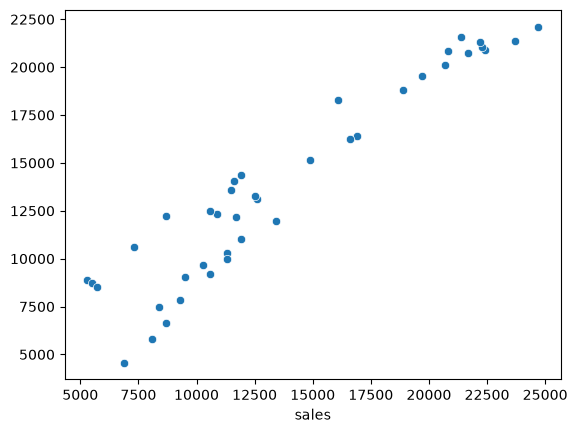

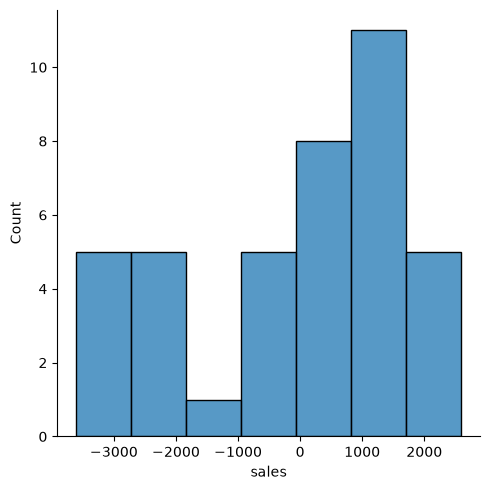

In [14]:
#Gráficos de Evaluación
sns.scatterplot(x=y_test, y=y_pred_lineal)
sns.displot((y_test - y_pred_lineal))

In [15]:
#Métricas 
mae_lin = metrics.mean_absolute_error(y_test, y_pred_lineal)
mse_lin = metrics.mean_squared_error(y_test, y_pred_lineal)
rmse_lin = np.sqrt(metrics.mean_squared_error(y_test, y_pred_lineal))
r2_lin = lm.score(X_test_scal, y_test)

print(f'MAE: {mae_lin}')
print(f'MSE: {mse_lin}')
print(f'RMSE: {rmse_lin}')
print(f'R^2: {r2_lin}')

MAE: 1460.7567168117607
MSE: 3174097.353976108
RMSE: 1781.5996615334514
R^2: 0.8994380241009119


### Modelos Polinómicos

In [16]:
#2.Creo un polinómico de grado 2
poly = PolynomialFeatures(degree=2, include_bias=False)

In [17]:
#Transformo X_train y X_test
X_train_poly = poly.fit_transform(X_train_scal)
X_test_poly = poly.transform(X_test_scal)

In [18]:
#Entreno al modelo
lm_poly = LinearRegression()
lm_poly.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[3598.04,2857.61, 81.93,..., 28.94, 37.37, 11.49]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.477e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](9,)","[22. ,16.23,13.08,..., 9.76, 9.14, 7.45]"


In [19]:
#Predigo y evaluo
pred_poly = lm_poly.predict(X_test_poly)

mae_poly = metrics.mean_absolute_error(y_test, pred_poly)
mse_poly = metrics.mean_squared_error(y_test, pred_poly)
rmse_poly = np.sqrt(metrics.mean_squared_error(y_test, pred_poly))
r2_poly = lm_poly.score(X_test_poly, y_test)

print(f'MAE poly: {mae_poly}')
print(f'MSE poly: {mse_poly}')
print(f'RMSE poly: {rmse_poly}')
print(f'R^2 poly: {r2_poly}')

MAE poly: 526.1794444043742
MSE poly: 412910.22853789985
RMSE poly: 642.5809120553612
R^2 poly: 0.9869181490609604


In [20]:
#3.RIDGE
from sklearn.linear_model import Ridge
'''
ridgeR = Ridge(alpha = 0.001)
ridgeR.fit(X_train_scal, y_train)
'''

'\nridgeR = Ridge(alpha = 0.001)\nridgeR.fit(X_train_scal, y_train)\n'

In [21]:
#Predigo y evaluo
'''
pred_ridge = ridgeR.predict(X_test_scal)

mae_rid = metrics.mean_absolute_error(y_test, pred_ridge)
mse_rid = metrics.mean_squared_error(y_test, pred_ridge)
rmse_rid = np.sqrt(metrics.mean_squared_error(y_test, pred_ridge))
r2_rid = ridgeR.score(X_test_scal, y_test)

print(f'MAE ridge: {mae_rid}')
print(f'MSE ridge: {mse_rid}')
print(f'RMSE ridge: {rmse_rid}')
print(f'R^2 ridge: {r2_rid}')
'''

"\npred_ridge = ridgeR.predict(X_test_scal)\n\nmae_rid = metrics.mean_absolute_error(y_test, pred_ridge)\nmse_rid = metrics.mean_squared_error(y_test, pred_ridge)\nrmse_rid = np.sqrt(metrics.mean_squared_error(y_test, pred_ridge))\nr2_rid = ridgeR.score(X_test_scal, y_test)\n\nprint(f'MAE ridge: {mae_rid}')\nprint(f'MSE ridge: {mse_rid}')\nprint(f'RMSE ridge: {rmse_rid}')\nprint(f'R^2 ridge: {r2_rid}')\n"

In [22]:
#Me genero 100 alphas para ir probando
n_alphas = 100
alphas = np.logspace(-4, 3, n_alphas) 

In [23]:
coef_ridge = []
err_ridge = []
baseline = []

for a in alphas:
    ridge = Ridge(alpha=a)   #Entreno para cada alpha
    ridge.fit(X_train_scal, y_train)
    
    coef_ridge.append(ridge.coef_)   #Voy almacenando cada coef
    
    y_pred = ridge.predict(X_test_scal)
    ridge_error = metrics.mean_squared_error(y_pred, y_test)
    
    err_ridge.append(ridge_error)
    baseline.append(mse_lin)

In [24]:
min(err_ridge)  #Min error

3174099.2809461346

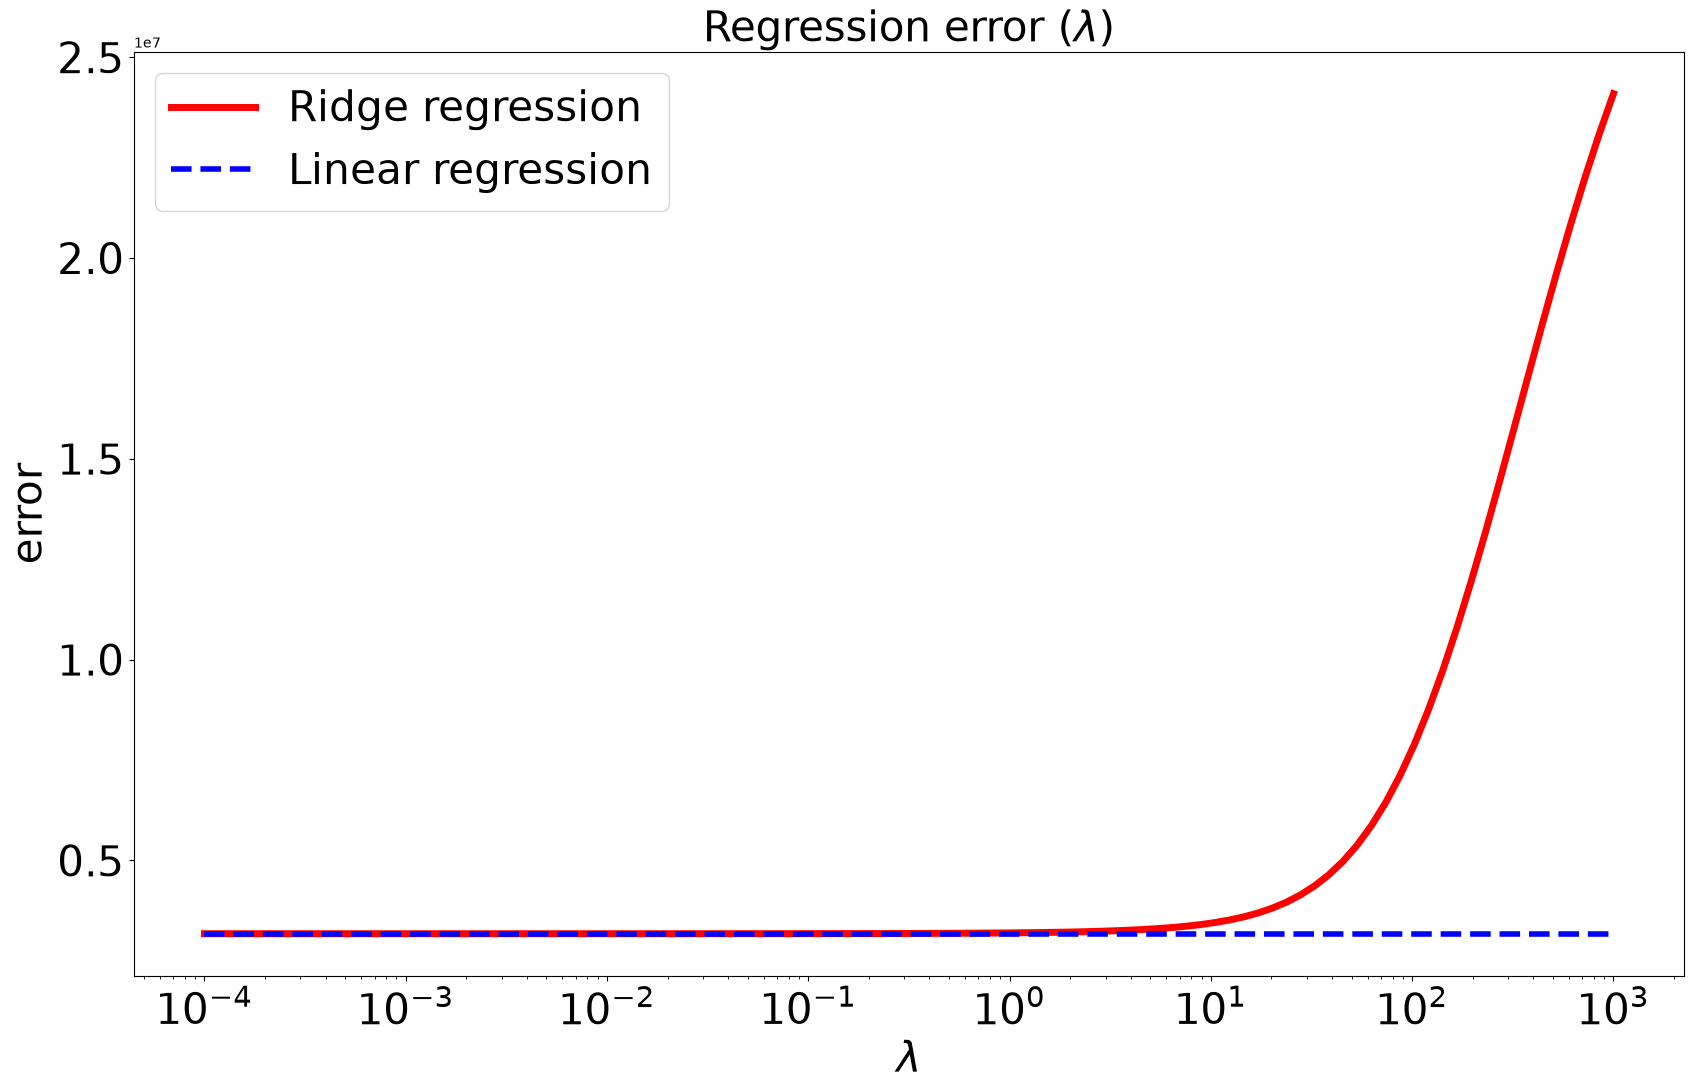

In [25]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_ridge, linewidth=5, color='red', label="Ridge regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [26]:
#Encuentro la posición (índice) del error mínimo
indice_min = np.argmin(err_ridge)

# Extrae el alpha y el error correspondientes a esa posición
mejor_alpha = alphas[indice_min]
minimo_error = err_ridge[indice_min]

print(f'Mejor alpha: {mejor_alpha}')
print(f'Mínimo error (MSE): {minimo_error}')

Mejor alpha: 0.0001
Mínimo error (MSE): 3174099.2809461346


In [27]:
ridgeR = Ridge(alpha = mejor_alpha)
ridgeR.fit(X_train_scal, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",np.float64(0.0001)
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == '

In [28]:
pred_ridge = ridgeR.predict(X_test_scal)

mae_rid = metrics.mean_absolute_error(y_test, pred_ridge)
mse_rid = metrics.mean_squared_error(y_test, pred_ridge)
rmse_rid = np.sqrt(metrics.mean_squared_error(y_test, pred_ridge))
r2_rid = ridgeR.score(X_test_scal, y_test)

print(f'MAE ridge: {mae_rid}')
print(f'MSE ridge: {mse_rid}')
print(f'RMSE ridge: {rmse_rid}')
print(f'R^2 ridge: {r2_rid}')

MAE ridge: 1460.7570753453524
MSE ridge: 3174099.2809461346
RMSE ridge: 1781.600202331077
R^2 ridge: 0.8994379630505118


In [29]:
#4.LASSO
from sklearn.linear_model import Lasso
'''
lassoR = Lasso(alpha=0.1)
lassoR.fit(X_train_scal, y_train)
'''

'\nlassoR = Lasso(alpha=0.1)\nlassoR.fit(X_train_scal, y_train)\n'

In [30]:
#Predigo y evaluo
'''
pred_lasso = lassoR.predict(X_test_scal)

mae_las = metrics.mean_absolute_error(y_test, pred_lasso)
mse_las = metrics.mean_squared_error(y_test, pred_lasso)
rmse_las = np.sqrt(metrics.mean_squared_error(y_test, pred_lasso))
r2_las = lassoR.score(X_test_scal, y_test)

print(f'MAE lasso: {mae_las}')
print(f'MSE lasso: {mse_las}')
print(f'RMSE lasso: {rmse_las}')
print(f'R^2 lasso: {r2_las}')
'''

"\npred_lasso = lassoR.predict(X_test_scal)\n\nmae_las = metrics.mean_absolute_error(y_test, pred_lasso)\nmse_las = metrics.mean_squared_error(y_test, pred_lasso)\nrmse_las = np.sqrt(metrics.mean_squared_error(y_test, pred_lasso))\nr2_las = lassoR.score(X_test_scal, y_test)\n\nprint(f'MAE lasso: {mae_las}')\nprint(f'MSE lasso: {mse_las}')\nprint(f'RMSE lasso: {rmse_las}')\nprint(f'R^2 lasso: {r2_las}')\n"

In [31]:
lasso = Lasso()

coef_lasso = []
err_lasso = []

for a in alphas:
    lasso.set_params(alpha=a)
    lasso.fit(X_train_scal, y_train)
    coef_lasso.append(lasso.coef_)
    y_pred = lasso.predict(X_test_scal)
    lasso_error = metrics.mean_squared_error(y_pred, y_test)    
    err_lasso.append(lasso_error)

In [32]:
# Obtener mejor alpha para Lasso
indice_min_lasso = np.argmin(err_lasso)
mejor_alpha_lasso = alphas[indice_min_lasso]
print(f'Mejor alpha Lasso: {mejor_alpha_lasso}')
print(f'Mínimo error Lasso (MSE): {err_lasso[indice_min_lasso]}')

Mejor alpha Lasso: 6.4280731172843195
Mínimo error Lasso (MSE): 3173904.896033045


In [33]:
lassoR = Lasso(alpha=mejor_alpha_lasso)
lassoR.fit(X_train_scal, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",np.float64(6.4280731172843195)
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [34]:
#Predigo y evaluo
pred_lasso = lassoR.predict(X_test_scal)

mae_las = metrics.mean_absolute_error(y_test, pred_lasso)
mse_las = metrics.mean_squared_error(y_test, pred_lasso)
rmse_las = np.sqrt(metrics.mean_squared_error(y_test, pred_lasso))
r2_las = lassoR.score(X_test_scal, y_test)

print(f'MAE lasso: {mae_las}')
print(f'MSE lasso: {mse_las}')
print(f'RMSE lasso: {rmse_las}')
print(f'R^2 lasso: {r2_las}')

MAE lasso: 1459.6009377536836
MSE lasso: 3173904.896033045
RMSE lasso: 1781.5456480351675
R^2 lasso: 0.8994441215670176


In [35]:
#5.ELASTIC NET
elastic_net = ElasticNet(alpha = 0.01, l1_ratio = 0.5)
elastic_net.fit(X_train_scal, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",0.01
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet<sphx_glr_auto_examples_linear_model_plot_elastic_net_precomputed_gram_matrix_with_weighted_samples.py>`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [36]:
pred_elastic = elastic_net.predict(X_test_scal)

mae_ela = metrics.mean_absolute_error(y_test, pred_elastic)
mse_ela = metrics.mean_squared_error(y_test, pred_elastic)
rmse_ela = np.sqrt(metrics.mean_squared_error(y_test, pred_elastic))
r2_ela = elastic_net.score(X_test_scal, y_test)

print(f'MAE elastic: {mae_ela}')
print(f'MSE elastic: {mse_ela}')
print(f'RMSE elastic: {rmse_ela}')
print(f'R^2 elastic: {r2_ela}')

MAE elastic: 1463.5979314138915
MSE elastic: 3190019.5413836027
RMSE elastic: 1786.0625804779638
R^2 elastic: 0.8989335762381746


## Resultados

In [37]:
# Interpreta, resume y destaca los puntos importantes de los resultados.

In [38]:
# Utiliza todas las celdas que necesites...

In [39]:
resultados = pd.DataFrame({
    'Modelo': ['Regresión Lineal', 'Polinómica (Grado 2)', 'Ridge', 'Lasso', 'ElasticNet'],
    'MAE': [mae_lin, mae_poly, mae_rid, mae_las, mae_ela],
    'RMSE': [rmse_lin, rmse_poly, rmse_rid, rmse_las, rmse_ela],
    'R2': [r2_lin, r2_poly, r2_rid, r2_las, r2_ela]
})

resultados.sort_values(by='RMSE')

,Modelo,MAE,RMSE,R2
1,Polinómica (Grado 2),526.179444,642.580912,0.986918
3,Lasso,1459.600938,1781.545648,0.899444
0,Regresión Lineal,1460.756717,1781.599662,0.899438
2,Ridge,1460.757075,1781.600202,0.899438
4,ElasticNet,1463.597931,1786.062580,0.898934


In [40]:
#LA MEJOR OPCIÓN ES UNA POLINÓMICA DE GRADO "2"

In [41]:
#Entreno la polinómica de grado 2 sobre X_train sin escalar para leer los coeficientes en unidades reales
poly_real = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly_real = poly_real.fit_transform(X_train)

modelo_final = LinearRegression()
modelo_final.fit(X_train_poly_real, y_train)

nombres_vars = poly_real.get_feature_names_out(['TV', 'radio', 'newspaper'])
print(f"Intercepto (b0): {modelo_final.intercept_:.2f}\n")

for nombre, coef in zip(nombres_vars, modelo_final.coef_):
    print(f"{nombre:15s}: {coef:.4f}")

Intercepto (b0): 4939.01

TV             : 53.2356
radio          : 17.0980
newspaper      : 10.5807
TV^2           : -0.1123
TV radio       : 1.1112
TV newspaper   : -0.0738
radio^2        : 0.1328
radio newspaper: 0.1249
newspaper^2    : 0.0280
